# CS2 - Carbonate Reservoir Characterization & Rock Typing

**Case Study - Petrophys Curriculum**

Well **HW-10** (COSTA carbonate dataset, depths in **feet**): the **Kharaib-2** reservoir interval,
with core-corrected porosity and permeability curves.

---

**What you will learn**

- How to calibrate log porosity and saturation against core-derived reference curves - and what
  such a calibration can and cannot prove.
- Why a single porosity-permeability line fails in a carbonate, and how RQI/FZI flow units fix it.
- How to fit a Leverett J-function saturation-height model and cross-check it against log Sw.
- How to turn rock types and net pay into a completion recommendation.

**Prerequisites.** Part A lessons 04 (porosity), 06 (formation water and temperature), 07 (water
saturation), 08 (permeability) and 09 (reservoir quality and net pay); lesson 15 (capillary
pressure) helps for Section 4.5. The base install is enough.

## 1. The brief

> *"We have logged and cored the Kharaib-2 carbonate reservoir interval in well HW-10. Reservoir
> engineering needs a **rock-type profile** and a **reservoir-quality assessment**: where
> are the best flow units, how do porosity and permeability relate, is the interval
> hydrocarbon-bearing, and where should we complete? Calibrate everything to the core so the
> answer is defensible."*

**Who is asking:** the asset team's reservoir engineer, ahead of a completion decision.

**Why it matters.** Carbonates are notoriously heterogeneous: pore geometry (moldic, vuggy,
intercrystalline) decouples porosity from permeability, so a single porosity-permeability
line is meaningless. We must **partition** the rock into flow units (hydraulic flow units /
rock types) using the Amaefule Reservoir Quality Index (RQI) / Flow Zone Indicator (FZI)
framework, calibrate the log petrophysics to the core data, and then rank the reservoir.

**The deliverable (produced by the end of this lesson):**
1. A **rock-type / flow-unit track** vs depth.
2. A **poro-perm cloud** coloured by rock type, with the single transform line and
   constant-FZI reference lines.
3. **Core-vs-log calibration** crossplots (porosity and permeability).
4. A **saturation-height** curve from a fitted Leverett J-function.
5. A **reservoir-quality summary figure + table** and the best intervals to complete.

This case study *chains* many modules; it references the single-module tutorials rather than
re-teaching them.

In [1]:
%matplotlib inline
from petrophys.visualization import use_plot_style
use_plot_style()
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

import petrophys as pp

# Physics / interpretation modules used below
from petrophys.interpretation import porosity as poro
from petrophys.interpretation import saturation as sat
import petrophys.interpretation.saturation.height as sath
from petrophys.interpretation.temperature import calculate_temperature_profile, arps_equation
import petrophys.interpretation.core_analysis as core_mod
import petrophys.evaluation as res_mod

pd.set_option('display.width', 120)
pd.set_option('display.max_columns', 20)
print('petrophys', pp.__version__)
print('COSTA wells available:', pp.list_samples('costa'))

petrophys 3.0.0
COSTA wells available: ['HW-10', 'HW-24', 'HW-25', 'HW-26', 'HW-27', 'HW-28', 'HW-29', 'HW-3', 'HW-30', 'HW-31', 'HW-32', 'HW-4', 'HW-5', 'HW-6', 'HW-7', 'HW-8', 'HW-9']


## 2. The well & the data

HW-10 is one of 17 wells in the bundled **COSTA** carbonate dataset. Each COSTA LAS file covers
**only the Kharaib-2 reservoir interval**, not the whole well - so "the logged interval" and "the
Kharaib-2" are the same thing here. The bundled `formations_costa` table labels that interval;
we attach it when reading so plots and summaries carry the name.

Let's inventory exactly what we have - measured logs *and* core-derived curves - before planning
the workflow.

In [2]:
COSTA_TOPS = pp.sample('formations_costa')
well = pp.read(pp.sample('HW-10'), formations=COSTA_TOPS)
interval = pp.read_formations(COSTA_TOPS, well=well).iloc[0]

print('Well            :', well.name)
print('Depth unit      :', well.depth_unit)
print('Logged interval : %.1f - %.1f %s' % (well.top, well.bottom, well.depth_unit))
print('Reservoir zone  : %s (%.1f - %.1f %s in formations_costa)'
      % (interval['formation_name'], interval['top_depth'], interval['bottom_depth'], well.depth_unit))
print('Samples / step  : %d @ %.2f %s' % (well.n_samples, well.step, well.depth_unit))
print()
print('%-10s %-9s %6s %6s %10s %10s' % ('CURVE','UNIT','VALID','NULL','MIN','MAX'))
print('-'*56)
for m in well.curves:
    c = well.get(m)
    lo = np.nanmin(c.data) if c.valid_count() else float('nan')
    hi = np.nanmax(c.data) if c.valid_count() else float('nan')
    print('%-10s %-9s %6d %6d %10.3g %10.3g' %
          (m, c.unit or '-', c.valid_count(), c.null_count(), lo, hi))

Well            : HW-10
Depth unit      : ft
Logged interval : 8440.0 - 8630.0 ft
Reservoir zone  : KHARAIB-2 (8440.0 - 8630.0 ft in formations_costa)
Samples / step  : 381 @ 0.50 ft

CURVE      UNIT       VALID   NULL        MIN        MAX
--------------------------------------------------------
GR         gAPI         381      0       5.37       33.9
RHOB       g/cm3        381      0       2.25       2.75
NPHI       ft3/ft3      381      0       0.02       0.27
DT         us/ft          0    381        nan        nan
PHIE_CC    ft3/ft3      381      0          0       0.27
RT         ohm.m        381      0       0.22       38.2
SW_INPUT   v/v          160    221       0.38          1
PERM_CC    mD           311     70       0.04        345


**Reading the inventory.**

*Wireline logs:* `GR`, `RHOB`, `NPHI`, `RT` are complete. `DT` (sonic) is **all-null** - no
acoustic porosity available here.

*Core-derived curves* (the reason this well was chosen):
- `PHIE_CC` - core-corrected porosity curve (v/v) - per the LAS description a log-resolution
  "core corrected porosity input", not discrete plug measurements
- `PERM_CC` - core-corrected permeability curve (mD, log-resolution), covering a range of
  several orders of magnitude (see MIN/MAX above)
- `SW_INPUT` - a source-provided water saturation (fraction) over part of the interval. It is
  **not** a core or SCAL measurement, and it may itself be derived from these logs, so we
  treat it as a reference curve, not as ground truth.

The **very low GR** is the fingerprint of a *clean carbonate*: negligible clay. That
immediately shapes our model choices (Section 3).

In [3]:
# Load header Archie parameters LIVE - these ship with the LAS and must not be invented.
RW  = well.get_parameter('RW')    # water resistivity at RWT
A   = well.get_parameter('A')     # tortuosity
M   = well.get_parameter('M')     # cementation exponent
N   = well.get_parameter('N')     # saturation exponent
BHT = well.get_parameter('BHT')   # bottom-hole temperature (deg F)
RWT = well.get_parameter('RWT')   # temperature at which RW is quoted (deg F)

print('Archie / petrophysical header parameters (read from the LAS):')
print('  RW  = %.4f ohm.m  (quoted at RWT = %.0f deg F)' % (RW, RWT))
print('  A   = %.3f' % A)
print('  M   = %.3f  (cementation exponent)' % M)
print('  N   = %.3f  (saturation exponent)' % N)
print('  BHT = %.0f deg F  (bottom-hole temperature)' % BHT)

Archie / petrophysical header parameters (read from the LAS):
  RW  = 0.1373 ohm.m  (quoted at RWT = 68 deg F)
  A   = 1.000
  M   = 2.030  (cementation exponent)
  N   = 2.000  (saturation exponent)
  BHT = 251 deg F  (bottom-hole temperature)


## 3. Workflow plan (and why in this order)

| # | Step | Module | Why here |
|---|------|--------|----------|
| 1 | Porosity from RHOB/NPHI (limestone matrix) | `petrophys.interpretation.porosity` | An **independent** log porosity to calibrate against core |
| 2 | Temperature-correct RW, then Archie Sw | `petrophys.interpretation.temperature`, `petrophys.interpretation.saturation` | Clean carbonate -> Archie is valid; RW must be at formation T |
| 3 | Core-log calibration (porosity + poro-perm transform) | `petrophys.interpretation.core_analysis` | Tie the logs to the core-corrected curves; expose poro-perm scatter |
| 4 | RQI / FZI flow units -> rock types | `petrophys.evaluation` (`calculate_flow_units`) | Partition the heterogeneous carbonate into hydraulic flow units |
| 5 | Saturation-height (fit Leverett J) | `petrophys.interpretation.saturation.height` | Physically-based Sw model; cross-check vs log Sw |
| 6 | Net pay with Costa project cutoffs | `petrophys.evaluation` (`calculate_net_pay`) | Turn interpretation into a completion recommendation |

**Why individual functions instead of `pp.interpret`?** The one-call workflow (CS1, lesson 10)
is the right tool for a standard interpretation. This deliverable needs the intermediate results -
the calibration statistics, the flow-unit clustering, the J-function fit - so we call the physics
functions directly and keep every step visible.

**Why Archie (and not a shaly-sand model)?** Archie's law assumes the rock matrix is a perfect
insulator and all conductivity comes from brine in the pores:

$$S_w^{\,n} = \frac{a\,R_w}{\phi^{m}\,R_t}$$

That assumption holds for a **clean** carbonate (very low GR, negligible clay-bound water).
If GR were high, or if independent evidence showed dispersed clay / conductive minerals, we
would switch to **Waxman-Smits** or **Dual-Water**, which add a clay-conductivity term (CEC /
bound-water) and need inputs the logs do not give (a laboratory CEC with its
counter-ion conductance $B$, or the bound-water resistivity $R_{wb}$), which the default
interpretation workflow does not estimate. We keep those in reserve and justify the Archie choice from the
data.

> Note the header **M** printed above - slightly above the classic 2.0 - which is typical for
> carbonates where cementation reduces pore connectivity.

## 4. Execution

### 4.1 Independent log porosity (limestone matrix)

For a clean limestone we take the matrix density as **2.71 g/cc** (calcite) and a brine density of
**1.1 g/cc** for the density porosity (COSTA formation waters are about 200,000 ppm; the library's
COSTA calibration uses the same value), then combine density + neutron. This gives a log
porosity that is *independent* of the core `PHIE_CC` - essential, because calibrating
`PHIE_CC` against itself would be trivially perfect and tell us nothing.

Where the two logs cross over (density porosity more than 0.05 above neutron porosity), we take
density porosity (`gas_method='density'`): the Kharaib-2 is oil-bearing, and that is the rule
`pp.interpret` applies with its default `hc_type='oil'`. The function's default there, the
root-mean-square of Gaymard and Poupon (1968), is a gas-zone approximation. HW-10 has no crossover
samples, so the choice does not change its numbers; it does for some of the other COSTA wells
(section 8 and CS3).

In [4]:
rhob = well.get('RHOB').data
nphi = well.get('NPHI').data

RHOB_MATRIX = 2.71   # calcite / limestone
RHOB_FLUID  = 1.10   # saline brine (~200,000 ppm), as in the library's COSTA calibration

phid = poro.density_porosity(rhob, rhob_matrix=RHOB_MATRIX, rhob_fluid=RHOB_FLUID)
phit = poro.total_porosity(nphi, phid, method='adaptive',
                          gas_method='density')   # combine N & D; density porosity in crossover (oil)
phit = np.clip(phit, 0.0, 0.45)

well.add_curve('PHIT_LOG', phit, unit='v/v', description='Log total porosity (N-D, limestone)')

print('Log porosity (N-D, limestone matrix):')
print('  mean = %.3f  p10 = %.3f  p50 = %.3f  p90 = %.3f' %
      (np.nanmean(phit), np.nanpercentile(phit,10),
       np.nanpercentile(phit,50), np.nanpercentile(phit,90)))
print('Core PHIE_CC for reference:')
cc = well.get('PHIE_CC').data
print('  mean = %.3f  p10 = %.3f  p50 = %.3f  p90 = %.3f' %
      (np.nanmean(cc), np.nanpercentile(cc,10),
       np.nanpercentile(cc,50), np.nanpercentile(cc,90)))

Log porosity (N-D, limestone matrix):
  mean = 0.188  p10 = 0.016  p50 = 0.233  p90 = 0.265
Core PHIE_CC for reference:
  mean = 0.182  p10 = 0.000  p50 = 0.230  p90 = 0.260


### 4.2 Water saturation - the RW temperature correction that makes Archie work

The header quotes `RW = 0.1373 ohm.m` **at RWT = 68 deg F** (a lab / surface temperature). Down
at reservoir conditions (BHT ~ 251 deg F) brine is far more conductive, so its resistivity is
much lower. Using the surface RW directly makes $R_o = a R_w / \phi^m$ far too large, Archie
returns $S_w$ at or above 1 almost everywhere (only the best rock stays just below), and the
answer is garbage.

The fix is the classic **Arps** temperature correction of RW from RWT to the formation
temperature at each depth, using a temperature profile built from the BHT.

In [5]:
# Build a temperature profile from surface (68 F) to BHT.
tprof = calculate_temperature_profile(well, bht=BHT, surface_temp=RWT)
tf = tprof.temperature   # deg F at each depth
print('Formation temperature over reservoir: %.0f - %.0f deg F (mean %.0f)'
      % (np.nanmin(tf), np.nanmax(tf), np.nanmean(tf)))

# Arps-correct RW from RWT (68 F) to formation temperature at each depth.
rw_fm = arps_equation(RW, RWT, tf)
print('RW at surface  (RWT=%.0f F) : %.4f ohm.m' % (RWT, RW))
print('RW at formation T (mean)   : %.4f ohm.m  <- much lower, as expected' % np.nanmean(rw_fm))

Formation temperature over reservoir: 241 - 245 deg F (mean 243)
RW at surface  (RWT=68 F) : 0.1373 ohm.m
RW at formation T (mean)   : 0.0411 ohm.m  <- much lower, as expected


In [6]:
rt = well.get('RT').data

# Archie with formation-temperature RW and the REAL header m, n, a.
sw_raw = sat.archie(rt, rw_fm, phit, a=A, m=M, n=N)
sw = np.clip(sw_raw, 0.0, 1.0)
well.add_curve('SW_ARCHIE', sw, unit='v/v', description='Archie Sw (RW @ formation T)')

# Compare against the source-provided SW_INPUT reference where it exists.
sw_ref = well.get('SW_INPUT').data
m_cmp = np.isfinite(sw_ref) & np.isfinite(sw)
r = np.corrcoef(sw[m_cmp], sw_ref[m_cmp])[0, 1]
sw_bias = np.nanmean(sw[m_cmp] - sw_ref[m_cmp])
print('Archie Sw vs source SW_INPUT:')
print('  n overlap points  = %d' % m_cmp.sum())
print('  correlation r     = %.3f' % r)
print('  mean Archie Sw    = %.3f' % np.nanmean(sw[m_cmp]))
print('  mean SW_INPUT     = %.3f' % np.nanmean(sw_ref[m_cmp]))
print('  bias (log - ref)  = %+.3f' % sw_bias)

Archie Sw vs source SW_INPUT:
  n overlap points  = 160
  correlation r     = 0.983
  mean Archie Sw    = 0.768
  mean SW_INPUT     = 0.669
  bias (log - ref)  = +0.099


The temperature-corrected Archie Sw **tracks the SW_INPUT reference closely** (correlation
printed above), which supports both the Archie choice and the RW correction. Because SW_INPUT is a
source-provided curve rather than a core measurement - it may even be derived from the same logs -
this is a consistency check, not an independent validation. The log reads higher than SW_INPUT on
average (the printed bias), which we carry forward as a known caveat.

### 4.3 Core-log calibration

`PHIE_CC` and `PERM_CC` are core-corrected reference curves, not independent raw plug
measurements. Wrapping them in `CoreData` demonstrates the calibration API, but does not
make them laboratory ground truth or establish independent validation.
We use the supplied curves for two calibration exercises:
1. **Porosity:** log `PHIT_LOG` vs core-corrected `PHIE_CC` -> bias / RMSE / regression.
2. **Poro-perm transform:** fit $\log_{10}(K) = A\,\phi + B$ on the core-corrected samples.

The poro-perm transform will show the *scatter* that motivates rock typing. (`SW_INPUT` goes
into `CoreData` only as the source-provided saturation reference.)

In [7]:
depth = well.depth
core = core_mod.CoreData(
    depth=depth,
    porosity=well.get('PHIE_CC').data,
    permeability=well.get('PERM_CC').data,
    sw=well.get('SW_INPUT').data,
)

# (a) Porosity calibration: independent LOG porosity vs CORE porosity.
cal = core_mod.calibrate_porosity(well, core, log_curve='PHIT_LOG')
print('POROSITY calibration  (log PHIT_LOG  vs  core PHIE_CC)')
print('  n points  = %d' % cal.n_points)
print('  R^2       = %.3f' % cal.r_squared)
print('  bias      = %+.4f v/v   (log minus core)' % cal.bias)
print('  RMSE      = %.4f v/v' % cal.rmse)
print('  slope     = %.3f   intercept = %+.4f' % (cal.slope, cal.intercept))
print()

# (b) Poro-perm transform on the core-corrected samples.
ppt = core_mod.fit_poro_perm_transform(core, min_perm=0.01)
print('PORO-PERM transform   log10(K) = A*phi + B')
print('  A = %.3f   B = %.3f' % (ppt.A, ppt.B))
print('  R^2 = %.3f   n = %d   RMSE(log10K) = %.3f'
      % (ppt.r_squared, ppt.n_points, ppt.rmse))
print('  -> predicted K at phi=0.20 : %.1f mD' % ppt.predict(0.20))

POROSITY calibration  (log PHIT_LOG  vs  core PHIE_CC)
  n points  = 320
  R^2       = 0.994
  bias      = +0.0047 v/v   (log minus core)
  RMSE      = 0.0064 v/v
  slope     = 1.034   intercept = -0.0026

PORO-PERM transform   log10(K) = A*phi + B
  A = 7.139   B = -1.079
  R^2 = 0.261   n = 310   RMSE(log10K) = 0.593
  -> predicted K at phi=0.20 : 2.2 mD


**Two very different R^2 values - and that is the whole point.**

- Porosity calibration R^2 is close to 1: the log porosity and the core-corrected porosity curve
  agree almost perfectly. Since that reference is itself a log-resolution corrected curve rather
  than independent plug measurements, this is a consistency check on the petrophysics rather than
  an independent core validation - but the two porosity sources do tell one story.
- The single poro-perm transform has a low R^2: *one* line explains only a small part of the
  permeability variance. In a carbonate, porosity alone does **not** predict permeability -
  pore geometry does. **This is exactly why we need rock typing (Section 4.4).**

### 4.4 Rock typing - RQI / FZI hydraulic flow units

The Amaefule *et al.* (1993) framework separates the pore-geometry effect from porosity:

$$RQI = 0.0314\sqrt{K/\phi} \quad\text{(um)}, \qquad
\phi_z = \frac{\phi}{1-\phi}, \qquad
FZI = \frac{RQI}{\phi_z}$$

Rock with a **constant FZI** falls on a single straight line in $\log RQI$ vs $\log\phi_z$
space and behaves as one hydraulic flow unit. We cluster the core samples into flow units with
`calculate_flow_units`.

> **API note:** `calculate_flow_units(perm, phi, ...)` takes
> **permeability FIRST**, then porosity - the opposite of RQI's visual order. Getting this
> backwards silently produces nonsense.

In [8]:
perm_cc = well.get('PERM_CC').data
phie_cc = well.get('PHIE_CC').data

good = np.isfinite(perm_cc) & np.isfinite(phie_cc) & (perm_cc > 0) & (phie_cc > 0)
K_c   = perm_cc[good]
PHI_c = phie_cc[good]
D_c   = depth[good]

# NOTE the argument order: permeability FIRST, porosity SECOND.
fu = res_mod.calculate_flow_units(K_c, PHI_c, method='kmeans', max_units=4)

print('Flow-unit clustering (core-corrected samples):')
print('  n samples      = %d' % good.sum())
print('  n flow units   = %d' % fu.n_units)
print('  FZI unit means = %s' % np.array2string(fu.fzi_unit_mean, precision=3))
print('  FZI boundaries = %s' % np.array2string(fu.fzi_boundaries, precision=3))
print('  sample counts  = %s' % fu.counts)

Flow-unit clustering (core-corrected samples):
  n samples      = 310
  n flow units   = 3
  FZI unit means = [0.286 0.581 1.795]
  FZI boundaries = [0.408 1.021]
  sample counts  = [190  77  43]


In [9]:
# Order rock types by ascending FZI so RRT1=poorest ... RRTn=best.
order = np.argsort(fu.fzi_unit_mean)
rank_of_unit = {int(u+1): int(np.where(order == u)[0][0] + 1) for u in range(fu.n_units)}
rrt = np.array([rank_of_unit[int(h)] for h in fu.hfu])   # 1..n_units, higher = better

rows = []
for rt_id in range(1, fu.n_units + 1):
    sel = rrt == rt_id
    rows.append({
        'RockType': 'RRT%d' % rt_id,
        'N_samples': int(sel.sum()),
        'Phi_mean': round(float(PHI_c[sel].mean()), 3),
        'K_median_mD': round(float(np.median(K_c[sel])), 2),
        'K_max_mD': round(float(K_c[sel].max()), 1),
        'RQI_mean': round(float(fu.rqi[sel].mean()), 3),
        'FZI_mean': round(float(fu.fzi[sel].mean()), 3),
        'Depth_top': round(float(D_c[sel].min()), 1),
        'Depth_base': round(float(D_c[sel].max()), 1),
    })
rt_table = pd.DataFrame(rows)
print('Per-rock-type statistics (RRT1 = poorest, RRT%d = best):' % fu.n_units)
print(rt_table.to_string(index=False))

best_rt = fu.n_units
best_sel = rrt == best_rt
print()
print('Best rock type = RRT%d : median K = %.1f mD, mean phi = %.3f'
      % (best_rt, np.median(K_c[best_sel]), PHI_c[best_sel].mean()))

Per-rock-type statistics (RRT1 = poorest, RRT3 = best):
RockType  N_samples  Phi_mean  K_median_mD  K_max_mD  RQI_mean  FZI_mean  Depth_top  Depth_base
    RRT1        190     0.227         2.20       5.8     0.089     0.293     8462.5      8613.5
    RRT2         77     0.207         5.67      25.7     0.159     0.599     8463.5      8614.5
    RRT3         43     0.205        42.40     345.3     0.494     1.986     8460.5      8615.0

Best rock type = RRT3 : median K = 42.4 mD, mean phi = 0.205


### 4.5 Saturation-height model (Leverett J-function)

A saturation-height function predicts Sw from *height above the free-water level (FWL)* and
rock quality - independent of resistivity. We fit a Leverett **J-function** that normalises
capillary pressure for permeability and porosity:

$$J = 0.21645\,\frac{P_c}{\sigma\cos\theta}\sqrt{K/\phi}, \qquad S_w = a\,J^{\,b}$$

We have the core-corrected K and phi and the source-provided `SW_INPUT` saturation, but no
laboratory $P_c$, so we reconstruct $P_c$ from **height above a FWL** (buoyancy:
$P_c = 0.433(\rho_w-\rho_{hc})\,h$). `SW_INPUT` approaches ~1 near the base of its coverage, so we
place the FWL just below it. The fit is therefore calibrated to a reference saturation curve, not to
capillary-pressure measurements.

Capillary height is vertical. `saturation_height_from_logs` measures it on a TVD curve when one is
named (`tvd_curve=`); HW-10 has none, so it takes the depth index as true vertical depth - valid for
a vertical well only - and warns that it does. We treat HW-10 as vertical, with the FWL on the same
depth index.

In [10]:
sw_c = well.get('SW_INPUT').data
print('SW_INPUT coverage: %.1f - %.1f ft' % (depth[np.isfinite(sw_c)].min(), depth[np.isfinite(sw_c)].max()))
FWL = 8540.0    # ft - just below the deepest SW_INPUT sample (Sw -> ~1 there)
SG_WATER, SG_HC = 1.00, 0.80
IFT, THETA = 30.0, 30.0   # oil-brine

mJ = (np.isfinite(sw_c) & np.isfinite(perm_cc) & np.isfinite(phie_cc)
      & (perm_cc > 0) & (phie_cc > 0) & (sw_c < 1.0))

height = FWL - depth[mJ]                                   # ft above FWL
pc     = sath.pc_from_height(height, sg_water=SG_WATER, sg_hc=SG_HC)
Jvals  = sath.leverett_j(pc, perm_cc[mJ], phie_cc[mJ], ift=IFT, theta=THETA)

okJ = np.isfinite(Jvals) & (Jvals > 0)
jmodel = sath.fit_j_function(Jvals[okJ], sw_c[mJ][okJ], form='power',
                             ift=IFT, theta=THETA, sg_hc=SG_HC)
print('Fitted J-function  Sw = a * J^b')
print('  a   = %.4f' % jmodel.a)
print('  b   = %.4f' % jmodel.b)
print('  R^2 = %.3f' % jmodel.r2)

SW_INPUT coverage: 8456.0 - 8537.0 ft
Fitted J-function  Sw = a * J^b
  a   = 0.4822
  b   = -0.1437
  R^2 = 0.572


In [11]:
# Predict Sw vs depth from the J-model + FWL, using the core-corrected K and phi.
sw_jh = sath.saturation_height_from_logs(well, jmodel, fwl_depth=FWL)
well.add_curve('SW_JHEIGHT', sw_jh, unit='v/v', description='Sw from J-function height model')

mcmp = np.isfinite(sw_jh) & np.isfinite(sw_ref)
print('Saturation-height Sw vs source SW_INPUT:')
print('  n overlap = %d' % mcmp.sum())
print('  corr r    = %.3f' % np.corrcoef(sw_jh[mcmp], sw_ref[mcmp])[0,1])
print('  mean J-height Sw = %.3f   mean SW_INPUT = %.3f'
      % (np.nanmean(sw_jh[mcmp]), np.nanmean(sw_ref[mcmp])))

Saturation-height Sw vs source SW_INPUT:
  n overlap = 151
  corr r    = 0.751
  mean J-height Sw = 0.654   mean SW_INPUT = 0.667


[temporary directory]\ipykernel_14484\1758606978.py:2: UserWarning: saturation_height_from_logs: no tvd_curve given, so the depth index is taken as true vertical depth, which holds for a vertical well only. Pass tvd_curve, on the datum of fwl_depth, for a deviated well.
  sw_jh = sath.saturation_height_from_logs(well, jmodel, fwl_depth=FWL)


### 4.6 Net pay with the Costa project cutoffs

Carbonate cutoffs differ from clastics: clay is negligible (so the Vcl cutoff is loose), but
because low-FZI micro-porosity holds immovable water, we apply a **porosity cutoff** and a
**Sw cutoff** to isolate movable-hydrocarbon rock. We use the **Costa project cutoff set**
(`Vcl < 0.30`, `PHIE > 0.10`, `Sw < 0.60`), deliberately tighter than the generic carbonate
standard because the Kharaib-2 is a high-porosity carbonate and the screen targets quality rock;
CS3 and lesson 18 use the same set. We pass `lithology='carbonate'` and set the Sw curve to our
temperature-corrected Archie result.

Two porosity details to keep in view:

- The curve we store as `PHIE` is the **N-D total porosity** `PHIT_LOG`. In this clean carbonate
  (GR below about 34 gAPI) total and effective porosity are nearly equal, so it stands in for
  effective porosity; in a shaly rock it would not.
- `calculate_net_pay` looks porosity up **by name and takes `PHIE_CC` ahead of `PHIE`**, depth by
  depth. Every HW-10 sample has `PHIE_CC`, so the porosity cutoff below is applied to the
  core-corrected curve, not to our log porosity. The cell prints the same cutoffs applied to the
  log porosity with `summarize_pay` (explicit arrays, as CS3 does) for comparison; the two agree
  closely here because the log porosity matches `PHIE_CC` (section 4.3).

In [12]:
# calculate_net_pay reads VCL, porosity and SW curves off the well by name.
gr = well.get('GR').data
vcl = np.clip((gr - 8.0) / (40.0 - 8.0), 0.0, 1.0)   # clean=8, clay=40 gAPI
well.add_curve('VCL',  vcl,  unit='v/v')
well.add_curve('PHIE', phit, unit='v/v')             # N-D total porosity (~effective here)
well.add_curve('SW',   sw,   unit='v/v')             # temperature-corrected Archie

# Costa project cutoffs: deliberately tighter than the generic carbonate standard,
# because the Kharaib-2 is a high-porosity carbonate and this screening targets
# quality rock. Same set across CS2 / CS3 / lesson 18.
COSTA_CUTOFFS = dict(vcl_cutoff=0.30, phie_cutoff=0.10, sw_cutoff=0.60)
print('Generic carbonate standard:', res_mod.STANDARD_CUTOFFS['carbonate'])
print('Costa project cutoffs     :', COSTA_CUTOFFS)
VCL_CUT, PHIE_CUT, SW_CUT = (COSTA_CUTOFFS["vcl_cutoff"],
                             COSTA_CUTOFFS["phie_cutoff"],
                             COSTA_CUTOFFS["sw_cutoff"])
npres = res_mod.calculate_net_pay(well, vcl_cutoff=VCL_CUT, phie_cutoff=PHIE_CUT,
                                  sw_cutoff=SW_CUT, lithology='carbonate')

print()
print('Net-pay summary, Kharaib-2 interval (Vcl<%.2f, PHIE>%.2f, Sw<%.2f):'
      % (VCL_CUT, PHIE_CUT, SW_CUT))
print('  Gross interval    : %6.1f ft' % npres.gross_thickness)
print('  Net reservoir     : %6.1f ft' % npres.net_reservoir_thickness)
print('  Net pay           : %6.1f ft' % npres.net_pay_thickness)
print('  Net/Gross (pay)   : %6.2f'    % (npres.net_pay_thickness / npres.gross_thickness))
print('  (porosity used by calculate_net_pay: PHIE_CC where present, which is every sample here)')

# For comparison only: the same cutoffs on the log N-D porosity, passed explicitly.
log_pay = res_mod.summarize_pay(well, vcl=vcl, phie=phit, sw=sw, vcl_cutoff=VCL_CUT,
                                phie_cutoff=PHIE_CUT, sw_cutoff=SW_CUT)
print('Same cutoffs on the log N-D porosity: net reservoir %.1f ft, net pay %.1f ft'
      % (log_pay.net_reservoir_thickness, log_pay.net_pay_thickness))

Generic carbonate standard: {'vcl_cutoff': 0.3, 'phie_cutoff': 0.045, 'sw_cutoff': 0.7}
Costa project cutoffs     : {'vcl_cutoff': 0.3, 'phie_cutoff': 0.1, 'sw_cutoff': 0.6}

Net-pay summary, Kharaib-2 interval (Vcl<0.30, PHIE>0.10, Sw<0.60):
  Gross interval    :  190.5 ft
  Net reservoir     :  148.5 ft
  Net pay           :   12.0 ft
  Net/Gross (pay)   :   0.06
  (porosity used by calculate_net_pay: PHIE_CC where present, which is every sample here)
Same cutoffs on the log N-D porosity: net reservoir 149.0 ft, net pay 12.0 ft


## 5. Integrated result - deliverable figures

Now the visual deliverables. First map the per-sample rock type back onto the full depth track,
then produce the six figures.

In [13]:
# Map rock type onto the full depth vector (NaN where no valid core sample).
rrt_full = np.full(len(depth), np.nan)
rrt_full[good] = rrt

# Predicted permeability from the single (uncalibrated) transform, for comparison lines.
phi_grid = np.linspace(0.01, 0.30, 50)
k_single = ppt.predict(phi_grid)

# Colour scheme for rock types (RRT1 poorest -> RRTn best).
rt_colors = ['#d7301f', '#e08214', '#1a9850', '#4575b4'][:fu.n_units]   # high-contrast on white
rt_cmap = ListedColormap(rt_colors)
print('Prepared depth-mapped rock types and transform grid.')

Prepared depth-mapped rock types and transform grid.


### Figure 1 - Rock-type / flow-unit track

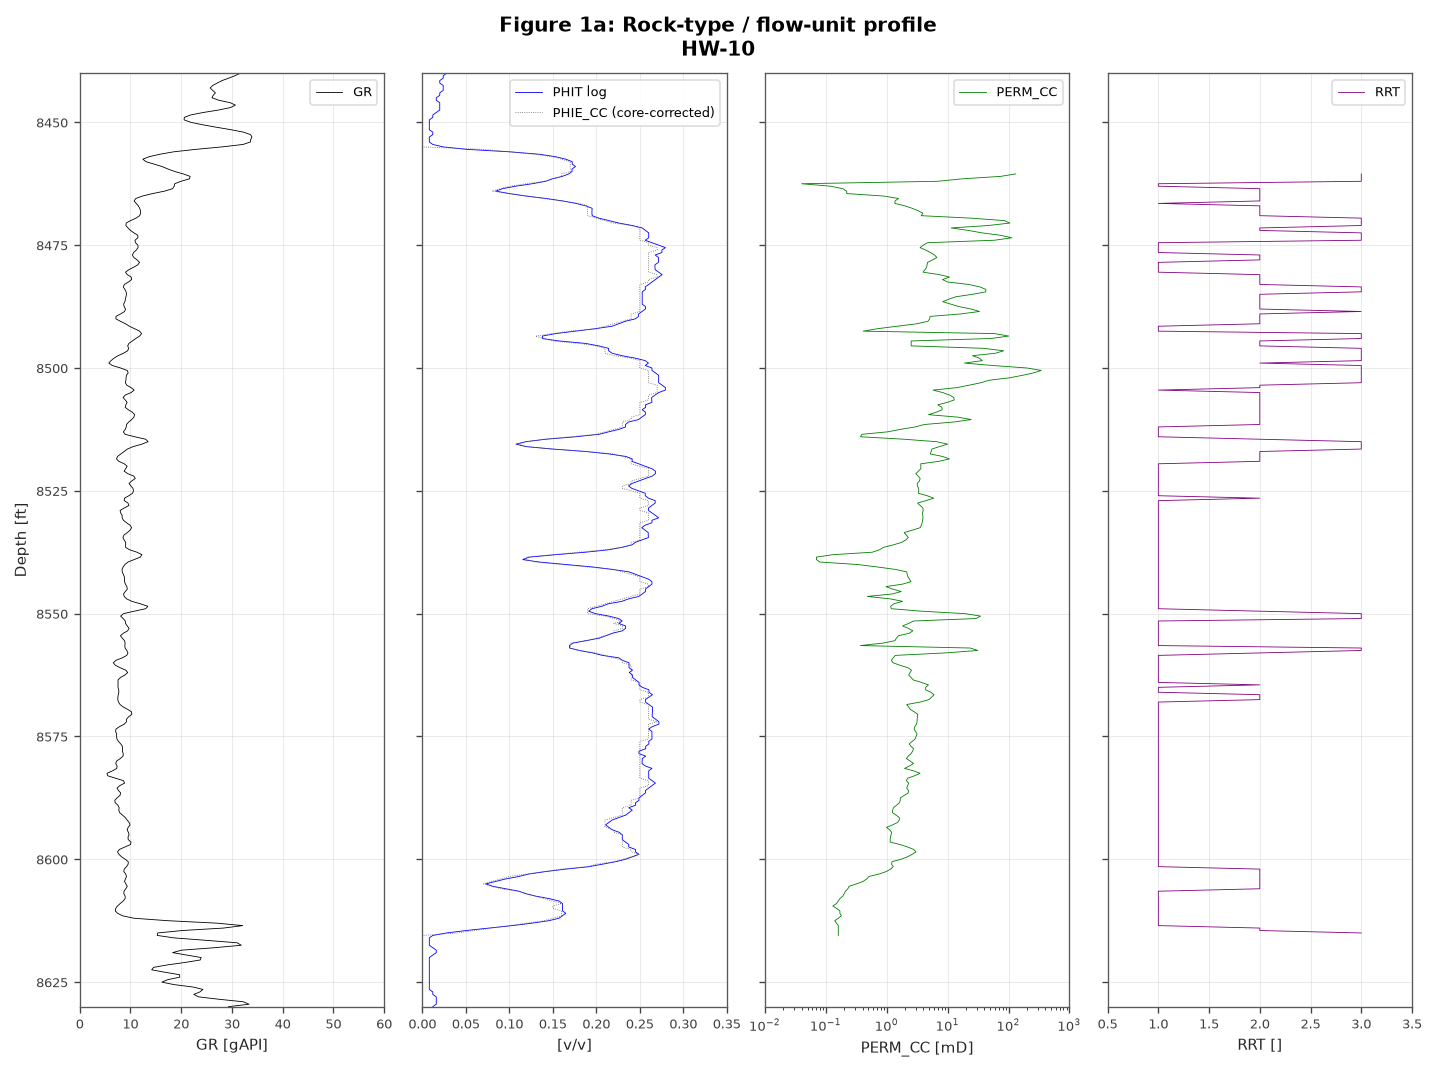

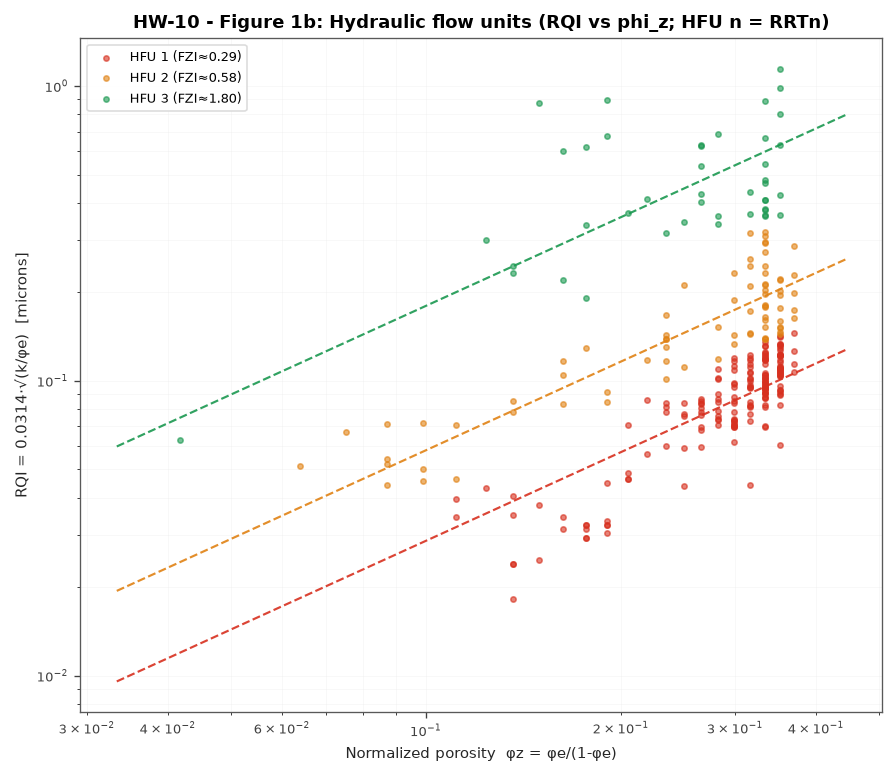

In [14]:
from petrophys.visualization import LogPlot, create_flow_unit_plot

# Attach the depth-mapped rock type so the library log plotter can render it.
well.add_curve('RRT', rrt_full, unit='', description='Reservoir rock type (1=poorest..n=best)')
if not well.has_curve('PHIE_CORE'):
    well.add_curve('PHIE_CORE', phie_cc, unit='v/v', description='Core PHIE_CC')

# Figure 1a: rock-type / flow-unit depth profile via the library LogPlot.
lp = LogPlot(well, figsize=(12, 9))
lp.create_figure(n_tracks=4)
lp.add_curve(0, 'GR', color='black', xlim=(0, 60))
lp.add_curve(1, 'PHIT_LOG', color='blue', xlim=(0, 0.35), label='PHIT log')
lp.add_curve(1, 'PHIE_CORE', color='0.4', linestyle=':', xlim=(0, 0.35), label='PHIE_CC (core-corrected)')
lp.add_curve(2, 'PERM_CC', color='green', log_scale=True, xlim=(0.01, 1000))
lp.add_curve(3, 'RRT', color='purple', xlim=(0.5, fu.n_units + 0.5))
lp.set_depth_range()
lp.add_title('Figure 1a: Rock-type / flow-unit profile')
lp.show()

# Figure 1b: the Amaefule RQI vs phi_z flow-unit diagnostic (the physics behind
# the rock-type partition) rendered by the library flow-unit plotter. The units are
# numbered by ascending FZI, so HFU n = RRTn; rt_cmap keeps the rock-type colours
# of the later figures (red = poorest, green = best).
create_flow_unit_plot(result=fu, cmap=rt_cmap,
                      title='HW-10 - Figure 1b: Hydraulic flow units (RQI vs phi_z; HFU n = RRTn)')
plt.show()

### Figure 2 - Poro-perm cloud coloured by rock type, with constant-FZI lines

The classic diagnostic. A single line (dashed) fits poorly; each rock type instead clusters around
its own constant-FZI reference line (dotted grey, one per rock-type mean FZI). These lines are
Kozeny-Carman curves for the class means, not separate regressions fitted to each rock type.

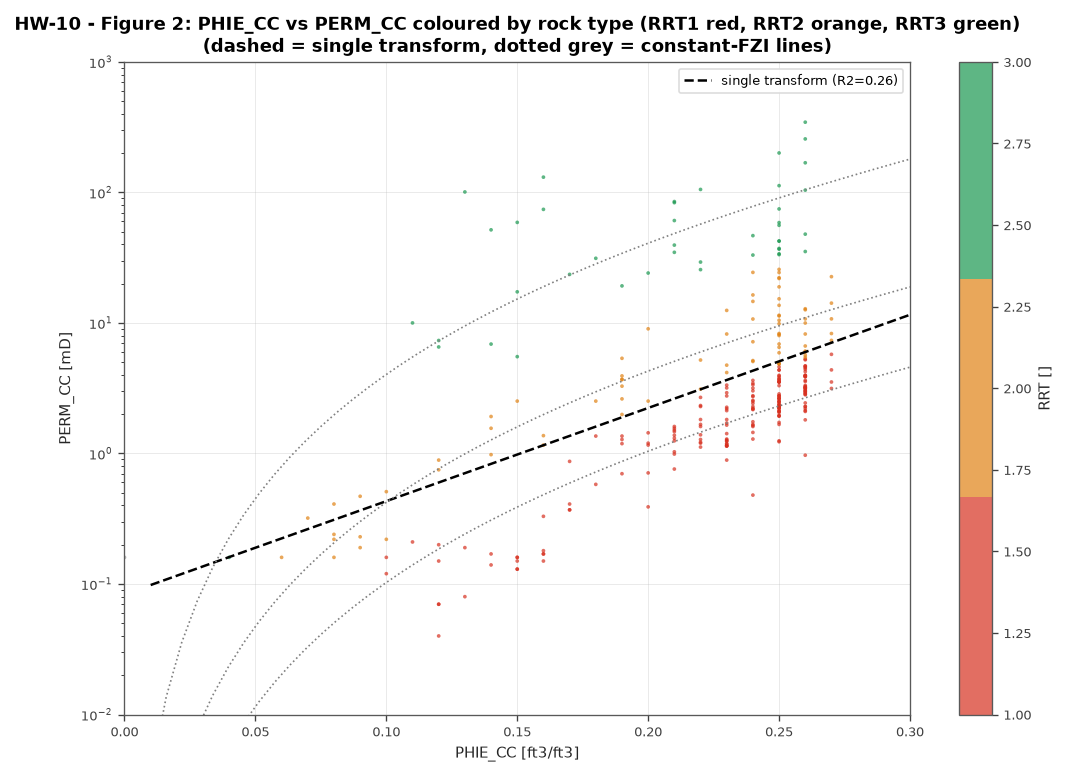

In [15]:
from petrophys.visualization import create_crossplot

# Figure 2: poro-perm cloud coloured by rock type, rendered by the library
# crossplot. RRT and the core curves are already on the well, so the crossplot
# colour-codes each sample by its flow unit directly.
cp = create_crossplot(
    well, 'PHIE_CC', 'PERM_CC', color_curve='RRT',
    y_log=True, xlim=(0, 0.30), ylim=(0.01, 1000), cmap=rt_cmap,   # same RRT colours as Figures 5-6
    figsize=(9, 6.5),
    title='HW-10 - Figure 2: PHIE_CC vs PERM_CC coloured by rock type (RRT1 red, RRT2 orange, RRT3 green)\n'
          '(dashed = single transform, dotted grey = constant-FZI lines)',
)

# Single global transform (dashed) - the poor fit.
cp.add_line(phi_grid, k_single, color='black', linestyle='--', linewidth=1.5,
            label='single transform (R2=%.2f)' % ppt.r_squared)

# Constant-FZI reference lines: K = 1014 * FZI^2 * phi^3/(1-phi)^2
for fzi_ref in fu.fzi_unit_mean:
    k_fzi = 1014.0 * fzi_ref**2 * phi_grid**3 / (1 - phi_grid)**2
    cp.add_line(phi_grid, k_fzi, color='grey', linestyle=':', linewidth=1.0)

cp.show()

### Figure 3 - Core-vs-log calibration crossplots

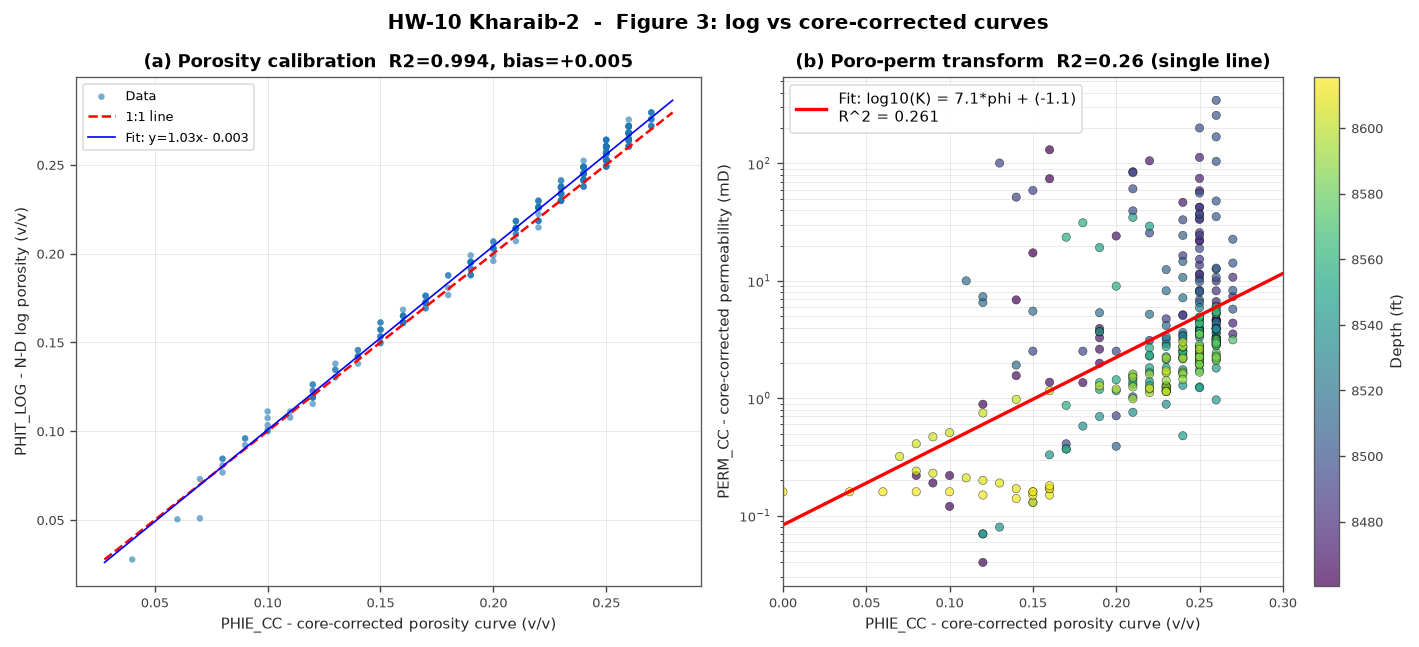

In [16]:
from petrophys.visualization.core import plot_calibration, plot_poro_perm

# Figure 3: core-vs-log calibration rendered by the library core plotters.
fig, axs = plt.subplots(1, 2, figsize=(12, 5.4))

# (a) porosity calibration crossplot (log PHIT vs core-corrected PHIE) with 1:1 + fit.
plot_calibration(cal, ax=axs[0], title='(a) Porosity calibration  R2=%.3f, bias=%+.3f'
                 % (cal.r_squared, cal.bias))
axs[0].set_xlabel('PHIE_CC - core-corrected porosity curve (v/v)')
axs[0].set_ylabel('PHIT_LOG - N-D log porosity (v/v)')
handles, labels = axs[0].get_legend_handles_labels()
axs[0].legend(handles, [lab.replace('+-', '- ') for lab in labels], loc='upper left', fontsize=8)

# (b) poro-perm crossplot with the fitted single transform overlaid (the poor fit
# that motivates rock typing).
plot_poro_perm(core, transform=ppt, ax=axs[1],
               title='(b) Poro-perm transform  R2=%.2f (single line)' % ppt.r_squared)
# The CoreData here wraps the core-corrected log-resolution curves, not plug measurements.
axs[1].set_xlabel('PHIE_CC - core-corrected porosity curve (v/v)')
axs[1].set_ylabel('PERM_CC - core-corrected permeability (mD)')
axs[1].set_xlim(0, 0.30)          # data range; keeps the fit line inside the data
fig.axes[-1].set_ylabel('Depth (ft)')   # colour bar of panel (b)

fig.suptitle('HW-10 Kharaib-2  -  Figure 3: log vs core-corrected curves', fontsize=12)
plt.tight_layout(); plt.show()

Panel (b) makes the case for rock typing visually: a single poro-perm line scatters
across two orders of magnitude, whereas in Figure 2 each rock type clusters around its own
constant-FZI line.

### Figure 4 - Saturation-height curve

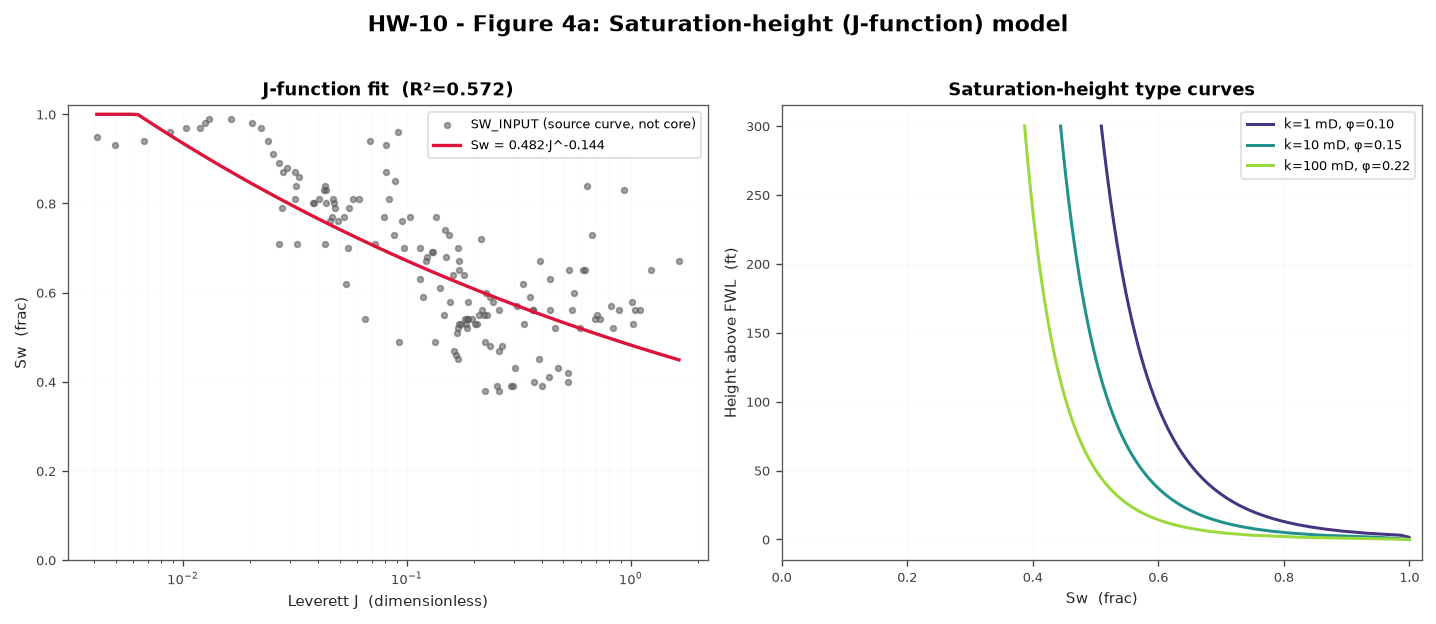

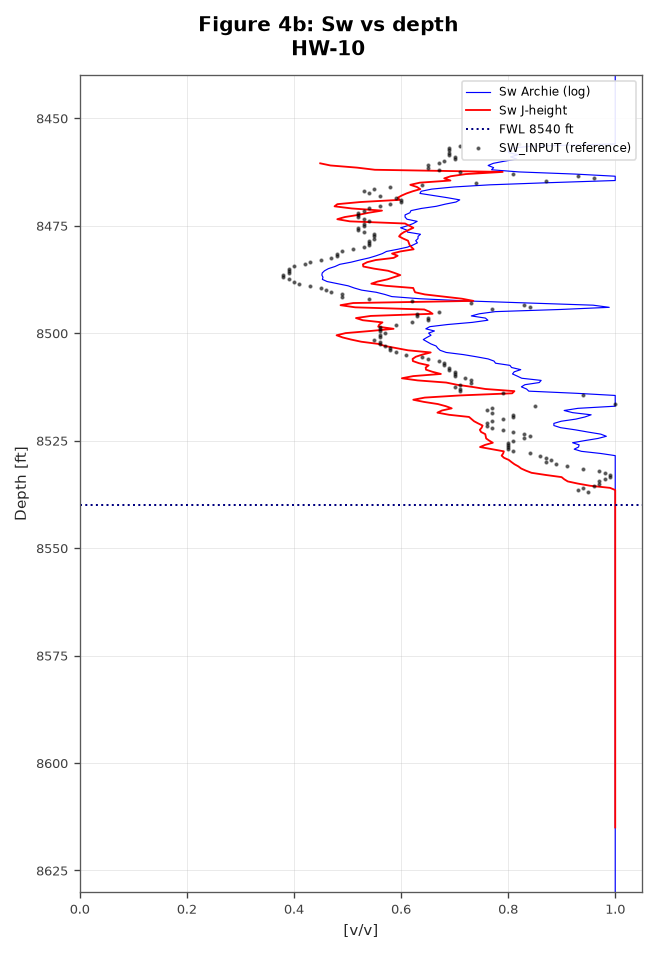

In [17]:
from petrophys.visualization import create_saturation_height_plot, LogPlot

# Figure 4a: the fitted Leverett J-function and the resulting Sw-vs-height type
# curves, rendered by the library saturation-height plotter (left = Sw vs J fit,
# right = Sw-height type curves for a poor/moderate/good rock triplet).
create_saturation_height_plot(
    jmodel, j=Jvals[okJ], sw=sw_c[mJ][okJ],
    title='HW-10 - Figure 4a: Saturation-height (J-function) model',
    data_label='SW_INPUT (source curve, not core)',
)
plt.show()

# Figure 4b: Sw vs depth cross-check - Archie log Sw, J-height Sw and SW_INPUT on a
# shared depth track via the library LogPlot (curves already on the well).
lp = LogPlot(well, figsize=(5.5, 8))
lp.create_figure(n_tracks=1)
lp.add_curve(0, 'SW_ARCHIE', color='blue', linewidth=0.7, xlim=(0, 1.05), label='Sw Archie (log)')
lp.add_curve(0, 'SW_JHEIGHT', color='red', linewidth=1.1, xlim=(0, 1.05), label='Sw J-height')
lp.axes[0].axhline(FWL, color='navy', ls=':', lw=1.2, label='FWL %.0f ft' % FWL)
lp.axes[0].plot(well.get('SW_INPUT').data, well.depth, 'k.', ms=3, alpha=0.5,
                label='SW_INPUT (reference)')
lp.axes[0].legend(loc='upper right', fontsize=7)
lp.set_depth_range()
lp.add_title('Figure 4b: Sw vs depth')
lp.show()

### Figure 5 - Reservoir-quality summary panel

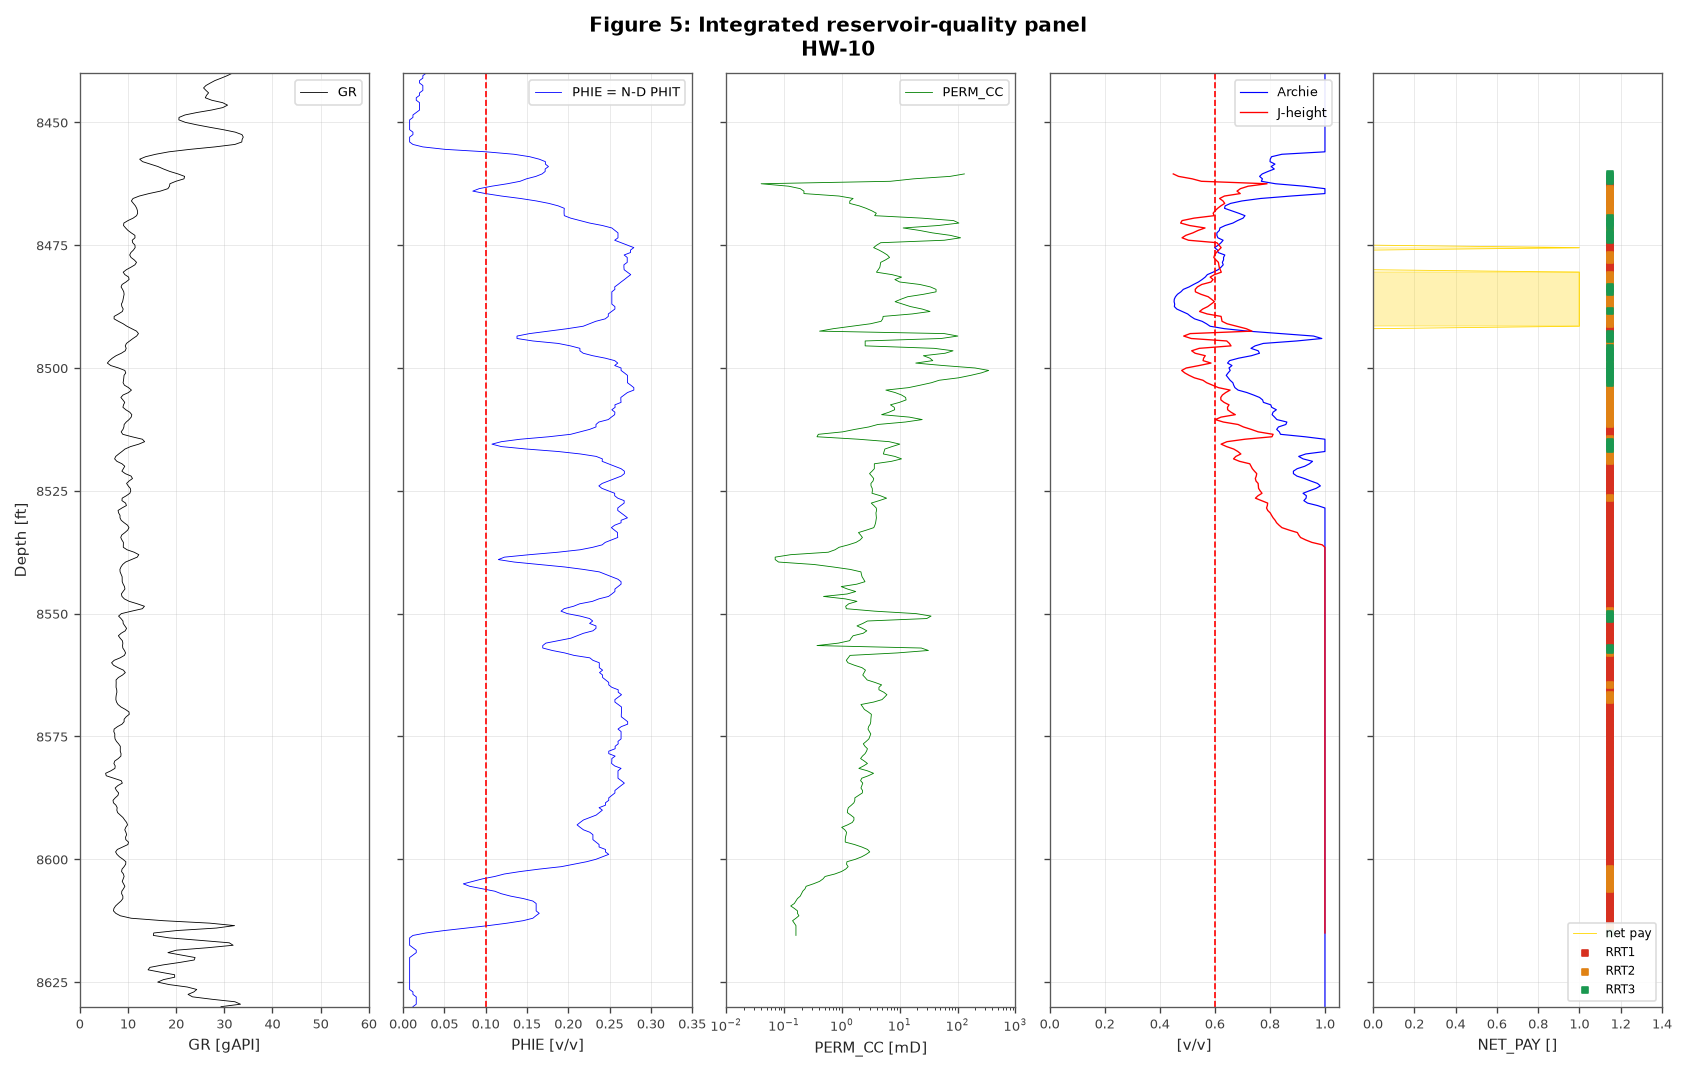

In [18]:
from petrophys.visualization import LogPlot

# Attach the net-pay flag so the library log plotter can shade it as its own track.
well.add_curve('NET_PAY', np.array(npres.net_pay, dtype=float), unit='',
               description='Net-pay flag (carbonate cutoffs)')

# Figure 5: integrated reservoir-quality panel via the library LogPlot.
lp = LogPlot(well, figsize=(14, 9))
lp.create_figure(n_tracks=5)
lp.add_curve(0, 'GR', color='black', xlim=(0, 60))
lp.add_curve(1, 'PHIE', color='blue', xlim=(0, 0.35), label='PHIE = N-D PHIT')
lp.axes[1].axvline(PHIE_CUT, color='r', ls='--', lw=1)
lp.add_curve(2, 'PERM_CC', color='green', log_scale=True, xlim=(0.01, 1000))
lp.add_curve(3, 'SW', color='blue', linewidth=0.7, xlim=(0, 1.05), label='Archie')
lp.add_curve(3, 'SW_JHEIGHT', color='red', linewidth=0.8, xlim=(0, 1.05), label='J-height')
lp.axes[3].axvline(SW_CUT, color='r', ls='--', lw=1)
lp.add_curve(4, 'NET_PAY', color='gold', xlim=(0, 1.4), label='net pay')
lp.add_fill(4, 'NET_PAY', 0.0, color='gold', where='right')
# overlay the rock-type squares alongside the net-pay flag
for rt_id in range(1, fu.n_units + 1):
    sel = rrt_full == rt_id
    lp.axes[4].scatter(np.full(int(sel.sum()), 1.15), well.depth[sel], s=10,
                       c=rt_colors[rt_id - 1], marker='s', label='RRT%d' % rt_id)
lp.axes[4].legend(loc='lower right', fontsize=7)
lp.set_depth_range()
lp.add_title('Figure 5: Integrated reservoir-quality panel')
lp.show()

### Figure 6 - Rock-type quality bars (deliverable summary)

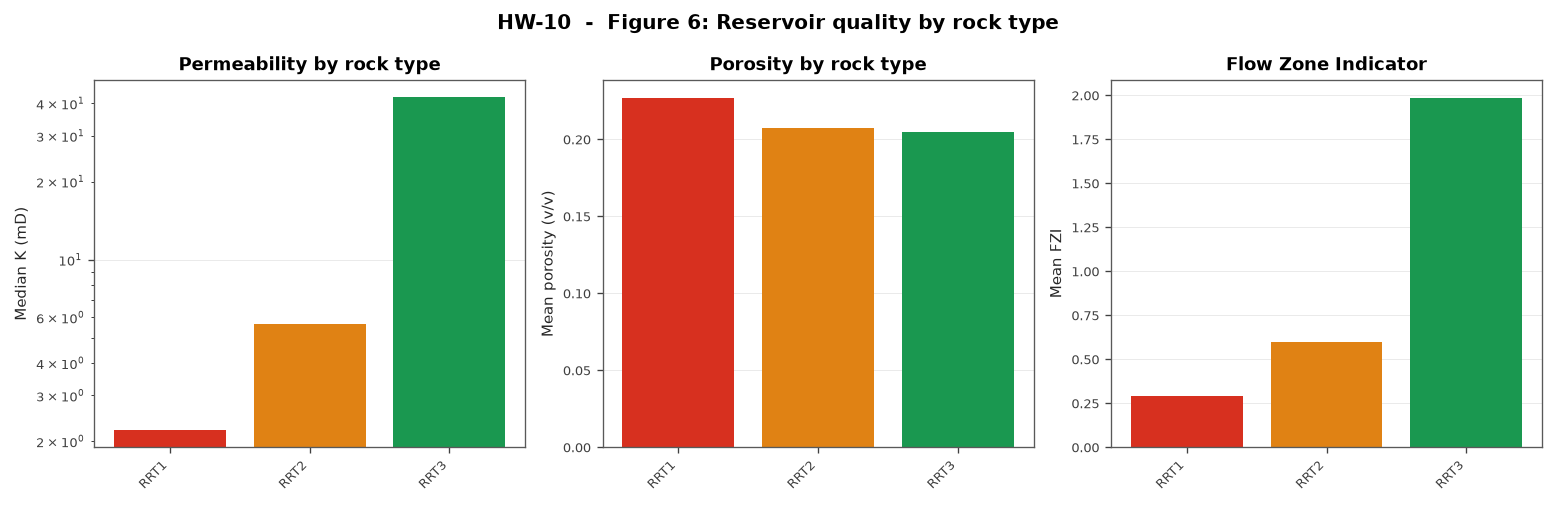

In [19]:
from petrophys.visualization import create_bar_comparison

# Figure 6: reservoir quality by rock type - three grouped bar charts via the
# library bar-comparison helper.
labels = ['RRT%d' % i for i in range(1, fu.n_units + 1)]
fig, axs = plt.subplots(1, 3, figsize=(13, 4.2))

create_bar_comparison(labels, rt_table['K_median_mD'].values, colors=rt_colors,
                      ylabel='Median K (mD)', title='Permeability by rock type', ax=axs[0])
axs[0].set_yscale('log')

create_bar_comparison(labels, rt_table['Phi_mean'].values, colors=rt_colors,
                      ylabel='Mean porosity (v/v)', title='Porosity by rock type', ax=axs[1])

create_bar_comparison(labels, rt_table['FZI_mean'].values, colors=rt_colors,
                      ylabel='Mean FZI', title='Flow Zone Indicator', ax=axs[2])

fig.suptitle('HW-10  -  Figure 6: Reservoir quality by rock type', fontsize=12)
plt.tight_layout(); plt.show()

### Reservoir-quality summary table

In [20]:
summary = rt_table.copy()
summary['Quality'] = ['Poor (tight/micro)', 'Fair', 'Good', 'Excellent'][:fu.n_units]
print('=== HW-10 KHARAIB-2 RESERVOIR-QUALITY SUMMARY ===')
print(summary.to_string(index=False))
print()
print('Kharaib-2 interval metrics:')
print('  Gross interval  : %.1f ft' % npres.gross_thickness)
print('  Net reservoir   : %.1f ft' % npres.net_reservoir_thickness)
print('  Net pay         : %.1f ft' % npres.net_pay_thickness)
print('  Log porosity vs core-corrected curve R^2 : %.3f (consistency check)' % cal.r_squared)
print('  Single poro-perm R^2     : %.2f (poor -> rock typing required)' % ppt.r_squared)

# How sensitive is net pay to the Sw cutoff? (Log Sw reads above SW_INPUT - see 4.2.)
print()
print('Net pay vs Sw cutoff (other cutoffs fixed):')
for cut in (0.50, 0.60, 0.70):
    alt = res_mod.calculate_net_pay(well, vcl_cutoff=VCL_CUT, phie_cutoff=PHIE_CUT,
                                    sw_cutoff=cut, lithology='carbonate')
    print('  Sw < %.2f : %5.1f ft' % (cut, alt.net_pay_thickness))

# Where is the pay, and which rock types make it up?
pay = np.asarray(npres.net_pay, dtype=bool)
best = rrt_full == fu.n_units
types, counts = np.unique(rrt_full[pay & np.isfinite(rrt_full)], return_counts=True)
print()
print('Net pay (Sw < %.2f) sits at %.1f - %.1f ft; rock types of pay samples: %s'
      % (SW_CUT, depth[pay].min(), depth[pay].max(),
         ', '.join('RRT%d x%d' % (t, c) for t, c in zip(types.astype(int), counts))))
print('RRT%d samples above the FWL (%.0f ft): %d of %d (median depth %.0f ft)'
      % (fu.n_units, FWL, np.sum(best & (depth < FWL)), best.sum(), np.median(depth[best])))

=== HW-10 KHARAIB-2 RESERVOIR-QUALITY SUMMARY ===
RockType  N_samples  Phi_mean  K_median_mD  K_max_mD  RQI_mean  FZI_mean  Depth_top  Depth_base            Quality
    RRT1        190     0.227         2.20       5.8     0.089     0.293     8462.5      8613.5 Poor (tight/micro)
    RRT2         77     0.207         5.67      25.7     0.159     0.599     8463.5      8614.5               Fair
    RRT3         43     0.205        42.40     345.3     0.494     1.986     8460.5      8615.0               Good

Kharaib-2 interval metrics:
  Gross interval  : 190.5 ft
  Net reservoir   : 148.5 ft
  Net pay         : 12.0 ft
  Log porosity vs core-corrected curve R^2 : 0.994 (consistency check)
  Single poro-perm R^2     : 0.26 (poor -> rock typing required)

Net pay vs Sw cutoff (other cutoffs fixed):
  Sw < 0.50 :   5.0 ft
  Sw < 0.60 :  12.0 ft
  Sw < 0.70 :  32.5 ft

Net pay (Sw < 0.60) sits at 8475.5 - 8491.5 ft; rock types of pay samples: RRT1 x3, RRT2 x17, RRT3 x4
RRT3 samples above the

## 6. Interpretation & deliverable

**Rock-type profile.** The core-corrected curves resolve into the hydraulic flow units in the
summary table above (RRT1 poorest to the highest RRT best):

- **RRT1 (poorest):** the bulk of the samples; porosity comparable to the better rock types but
  low permeability - classic carbonate **micro-porosity** that stores water but does not flow.
- **Intermediate rock types:** permeability rising with FZI at similar porosity.
- **Best rock type:** the sweet spot - median permeability roughly 20 times RRT1's at similar
  porosity (summary table), indicating better-connected pore geometry (interparticle /
  intercrystalline, or touching vugs). This is the flow unit to prioritise.

**Why porosity alone misled us.** Log porosity ties to the core-corrected porosity curve almost
perfectly (a consistency check), yet a single poro-perm line explains only a small part of the
permeability variance. Permeability - and hence deliverability - is controlled by *pore geometry*,
captured by FZI, not by porosity. Completing on a porosity cutoff alone would target water-filled
micro-porosity.

**Saturation model.** Archie is appropriate (clean carbonate, negligible clay). Once RW is
temperature-corrected from its 68 degF reference to formation temperature, log Sw tracks the
SW_INPUT reference closely. The J-function saturation-height model, calibrated to that same
reference, corroborates the profile above the FWL.

**Deliverable - reservoir-quality assessment of the HW-10 Kharaib-2 interval:**
- Net reservoir and net pay as printed above (porosity cutoff applied to `PHIE_CC`; the log
  porosity gives nearly the same thickness, section 4.6); net pay depends strongly on the Sw
  cutoff (the printed sensitivity), because this is a wet-leaning interval.
- **Where to complete:** the net pay is a thin zone in the **upper part of the interval, above
  the ~8540 ft FWL** (depths and rock types printed above). It is the only rock that combines a low
  enough Sw with mostly fair-to-good flow units (a few RRT1 samples sit among them), so it is the
  completion target. Below the FWL every rock
  type is wet.
- **Best flow unit = the highest rock type.** Its high-FZI streaks have the best deliverability;
  where they sit in or next to the pay zone, prioritise them for perforation. Elsewhere they read
  too wet for the Sw cutoff - revisit them if the Sw model or cutoff changes (net pay grows sharply
  at Sw < 0.70). RRT1 micro-porosity intervals, though porous, should be excluded.

## 7. Limitations & assumptions

- **Kharaib-2 only:** the LAS covers only this reservoir interval, so nothing here speaks to
  other zones in the well.
- **No sonic (DT all-null):** could not cross-check porosity with acoustic; relied on N-D with
  an assumed 2.71 g/cc limestone matrix. Dolomite stringers (matrix ~2.87) would bias porosity.
- **RW temperature correction is decisive:** using the 68 degF RW pushes Sw to or above 1 almost
  everywhere (only the best rock stays just below). We used the header BHT and an Arps
  correction; an error in BHT propagates directly to Sw.
- **Header RW and brine salinity disagree:** the header RW (0.1373 ohm.m at 68 degF) corresponds to
  roughly 50,000 ppm NaCl, far fresher than the ~200,000 ppm brine assumed for density porosity. A
  too-fresh Rw raises Archie Sw, which may explain part of the log's positive bias against
  `SW_INPUT`.
- **Archie assumption:** justified by low GR, but any conductive minerals or significant
  clay-bound water would require **Waxman-Smits** or **Dual-Water** (both available in
  `petrophys.interpretation.saturation`) and would lower the computed Sw.
- **No independent saturation truth:** `SW_INPUT` is a source-provided curve, not core or SCAL
  data; both the Archie check and the J-function fit lean on it.
- **Single poro-perm transform is intentionally poor** and must not be used for prediction;
  use the per-rock-type FZI classes instead.
- **FWL is inferred** from where SW_INPUT -> 1 (~8540 ft), not from pressure (RFT/MDT) data;
  the saturation-height curve inherits that uncertainty.
- **Net-pay porosity is `PHIE_CC`**, not the log porosity: `calculate_net_pay` takes the
  core-corrected curve by name wherever it exists (section 4.6). Pass explicit arrays to
  `summarize_pay` when the log porosity must drive the cutoff.
- **Log Sw reads above SW_INPUT** on average (bias printed in 4.2); the net-pay total moves
  materially across Sw cutoffs of 0.50-0.70 (printed in Section 5).
- Rock-type clustering uses **k-means** with `max_units=4`; the number of units the data
  support is printed in 4.4. A different `n_units`/method would shift boundaries.

## 8. Appendix - reproduce on another well

Every COSTA well (`pp.list_samples('costa')`) covers the Kharaib-2 interval with the same curve
names and header Archie parameters - except that a few wells lack header `M`/`N` (CS3 shows which
and how to handle them). The function below runs the core chain on any COSTA well that has them
and returns the flow-unit summary + net pay. As in section 4.6, `calculate_net_pay` applies the
porosity cutoff to `PHIE_CC` wherever a well has it and falls back to the log porosity elsewhere.

In [21]:
def rock_type_report(well_name, phie_cut=0.10, sw_cut=0.60):
    w = pp.read(pp.sample(well_name))
    rw  = w.get_parameter('RW');  rwt = w.get_parameter('RWT')
    a   = w.get_parameter('A');   m   = w.get_parameter('M')
    n   = w.get_parameter('N');   bht = w.get_parameter('BHT')
    if m is None or n is None:
        raise ValueError('%s has no header M/N; see CS3 for a flagged fallback' % well_name)

    rhob = w.get('RHOB').data; nphi = w.get('NPHI').data
    phid = poro.density_porosity(rhob, 2.71, 1.1)
    phi  = np.clip(poro.total_porosity(nphi, phid, method='adaptive', gas_method='density'), 0, 0.45)

    tp   = calculate_temperature_profile(w, bht=bht, surface_temp=rwt)
    rwfm = arps_equation(rw, rwt, tp.temperature)
    swv  = np.clip(sat.archie(w.get('RT').data, rwfm, phi, a=a, m=m, n=n), 0, 1)

    kc, pc = w.get('PERM_CC').data, w.get('PHIE_CC').data
    ok = np.isfinite(kc) & np.isfinite(pc) & (kc > 0) & (pc > 0)
    f  = res_mod.calculate_flow_units(kc[ok], pc[ok], method='kmeans', max_units=4)

    gr = w.get('GR').data
    w.add_curve('VCL', np.clip((gr-8)/(40-8), 0, 1))
    w.add_curve('PHIE', phi); w.add_curve('SW', swv)
    npr = res_mod.calculate_net_pay(w, vcl_cutoff=0.30, phie_cutoff=phie_cut,
                                    sw_cutoff=sw_cut, lithology='carbonate')
    return {'well': w.name, 'n_flow_units': f.n_units,
            'FZI_means': np.round(f.fzi_unit_mean, 3).tolist(),
            'net_pay_ft': round(npr.net_pay_thickness, 1),
            'net_res_ft': round(npr.net_reservoir_thickness, 1)}

for wn in ['HW-10', 'HW-3', 'HW-24']:
    print(rock_type_report(wn))

{'well': 'HW-10', 'n_flow_units': 3, 'FZI_means': [0.286, 0.581, 1.795], 'net_pay_ft': 12.0, 'net_res_ft': 148.5}
{'well': 'HW-3', 'n_flow_units': 4, 'FZI_means': [0.368, 0.705, 1.911, 10.142], 'net_pay_ft': 167.0, 'net_res_ft': 171.5}
{'well': 'HW-24', 'n_flow_units': 3, 'FZI_means': [0.388, 0.83, 3.657], 'net_pay_ft': 147.0, 'net_res_ft': 165.0}


---
### Recap
- Carbonate reservoir quality is controlled by **pore geometry (FZI)**, not porosity alone.
- **Calibrate to core-derived curves, and know what they are**: porosity ties tightly to the
  core-corrected curve; a single poro-perm line does not - use rock types. `SW_INPUT` is a
  reference curve, not core truth.
- **Temperature-correct RW** before Archie or Sw is nonsense.
- The deliverable is a **ranked rock-type profile** of the Kharaib-2 interval: the thin upper pay
  zone above the FWL is the completion target, and the best flow unit marks where to perforate
  first.

### Exercises
1. **Matrix sensitivity.** Recompute `PHIT_LOG` with a dolomite matrix (2.87 g/cc). How do the
   porosity calibration and net pay change?
2. **Flow-unit count.** Re-run `calculate_flow_units` with `max_units=3` and `max_units=5`. Which
   boundaries move, and does the best rock type keep the same depths?
3. **FWL uncertainty.** Move the FWL by +/-10 ft and refit the J-function. How much does the
   correlation with `SW_INPUT` change?

### See also / What's next
- Tutorials on porosity, saturation, and reservoir quality for the single-module mechanics.
- **CS3** scales this screening across the Kharaib-2 interval of all 17 COSTA wells.